# VAE-based with PyTorch
### Example with MNIST datas (possible 1D, 2D or 3D)
## 1. Import des bibliothèques python

In [24]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

# personnal
import libraries
import libraries.data_loader as dl
from libraries.display import display_group_images

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 2. Display training losses 

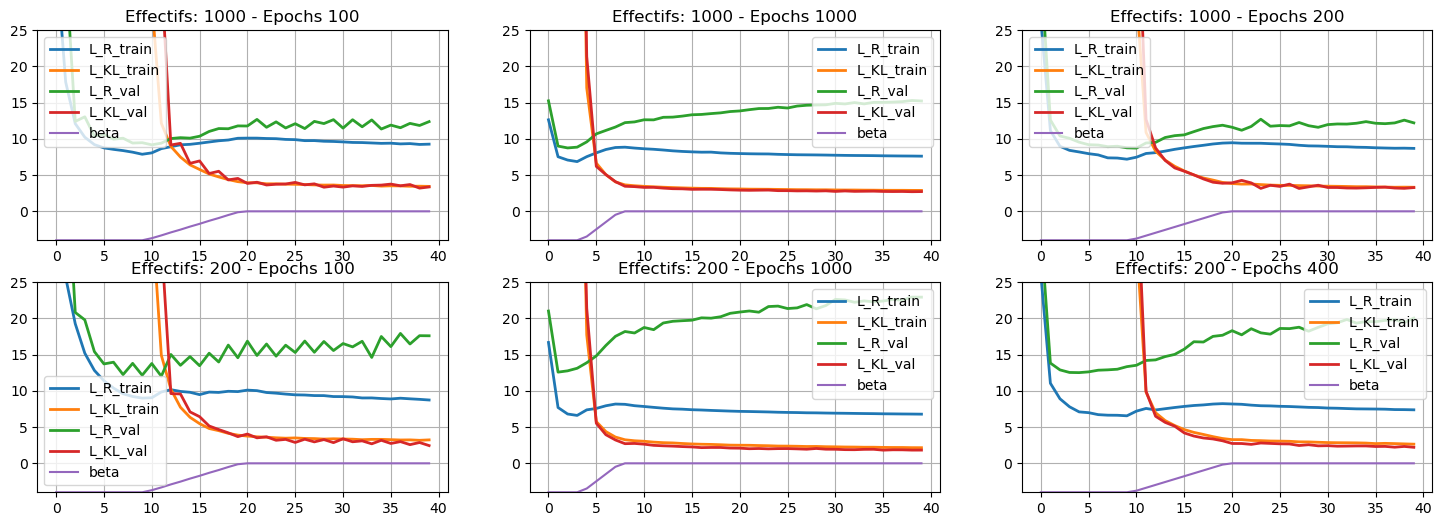

In [17]:
str_loss_colnames = ["L_ELBO", "L_R", "L_KL"]
reps = [f"results\\VAE\\{string}" for string in os.listdir(f"results\\VAE") if ("1.0" in string) and ("60000" not in  string)]
fig = plt.figure(len(reps), figsize = (18, 6))

for r, rep in enumerate(reps) :
    ef, ep = [int(e.split("_")[-1]) for e in rep.split("-")[-2:]]
    results_rep = f"results\\VAE\\D_50-beta_1.0-eff_{ef}-epoch_{ep}"
    
    AVG_loss = pd.read_csv(results_rep + "\\loss.csv")
    Val_loss = pd.read_csv(results_rep + "\\validation_loss.csv")
    learning_rates = pd.read_csv(results_rep + "\\learning_rate.csv")

    length = np.prod(np.array(AVG_loss).shape)
    length_2 = np.prod(np.array(Val_loss).shape)
    n = 40 
    idx = 0

    plt.subplot(2, 3, r+1)
    a_range = np.arange(idx, n)
    a_train = np.array(AVG_loss).reshape(n, length//(n*3), 3).mean(axis = 1)[:, 1:]
    a_val = np.array(Val_loss).reshape(n, length_2//(n*3), 3).mean(axis = 1)[:, 1:]
    a2 = np.array(learning_rates)[:, -1:].reshape(n, length//(n*3), 1).mean(axis = 1) *4 -4
    plt.plot(a_range, a_train[idx:], linewidth = 2)
    plt.plot(a_range, a_val[idx:], linewidth = 2)
    plt.plot(a_range, a2[idx:])
    plt.title(f"Effectifs: {ef} - Epochs {ep}")
    plt.grid()
    
    plt.ylim((-4, 25))
    plt.legend([s+"_train" for s in str_loss_colnames[1:]] + [s+"_val" for s in str_loss_colnames[1:]] + ["beta"])

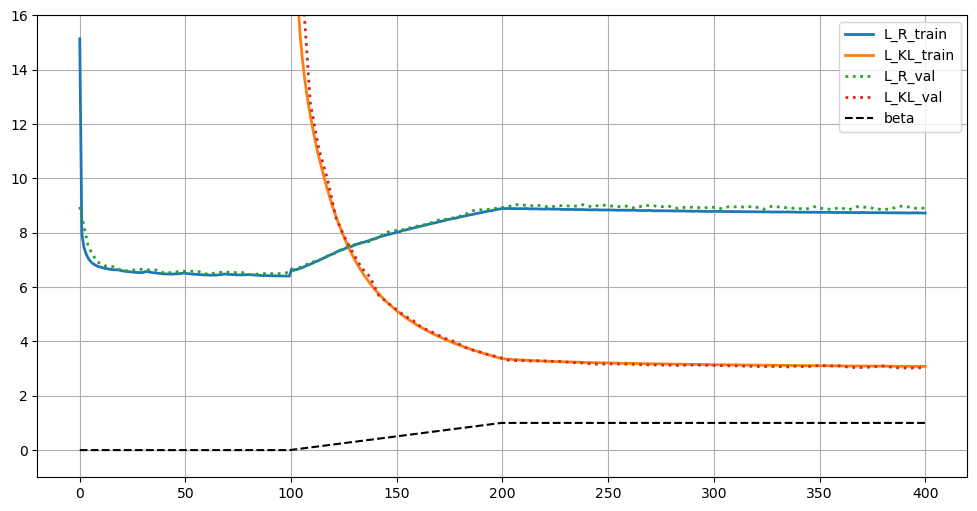

In [78]:
reps = os.listdir(f"results\\VAE")[-1:]
fig = plt.figure(len(reps), figsize = (12, 6))
D = 50
beta = 1.0
ef = 60000
epochs = [400]

for r, rep in enumerate(reps) :
    ep = epochs[r]
    results_rep = f"results\\VAE\\D_{D}-beta_{beta}-eff_{ef}-epoch_{ep}"
    
    AVG_loss = pd.read_csv(results_rep + "\\loss.csv")
    Val_loss = pd.read_csv(results_rep + "\\validation_loss.csv")
    learning_rates = pd.read_csv(results_rep + "\\learning_rate.csv")

    length = np.prod(np.array(AVG_loss).shape)
    length_2 = np.prod(np.array(Val_loss).shape)
    n = epochs[r]
    n_val = epochs[r]//4
    idx = 0

    plt.subplot(1, len(reps), r+1)
    a_range_train = np.linspace(idx, n, n)
    a_range_val = np.linspace(idx, n, n_val)
    a_train = np.array(AVG_loss).reshape(n, length//(n*3), 3).mean(axis = 1)[:, 1:]
    a_val = np.array(Val_loss).reshape(n_val, length_2//(n_val*3), 3).mean(axis = 1)[:, 1:]
    
    plt.plot(a_range_train, a_train[idx:], linewidth = 2)
    plt.plot(a_range_val, a_val[idx:], linewidth = 2, linestyle = "dotted")

    a2 = np.array(learning_rates)[:, -1:].reshape(n, length//(n*3), 1).mean(axis = 1)
    plt.plot(a_range_train, a2[idx:], color = "k", linestyle = "dashed")
    # plt.title(f"(Train;Val): ({ef};{10000}) - Epochs {ep}")
    plt.grid()
    
    plt.ylim((-1, 16))
    plt.legend([s+"_train" for s in str_loss_colnames[1:]] + [s+"_val" for s in str_loss_colnames[1:]] + ["beta"])

plt.savefig(f"results\\IMG\\training_loss.pdf", bbox_inches = "tight")
plt.show()

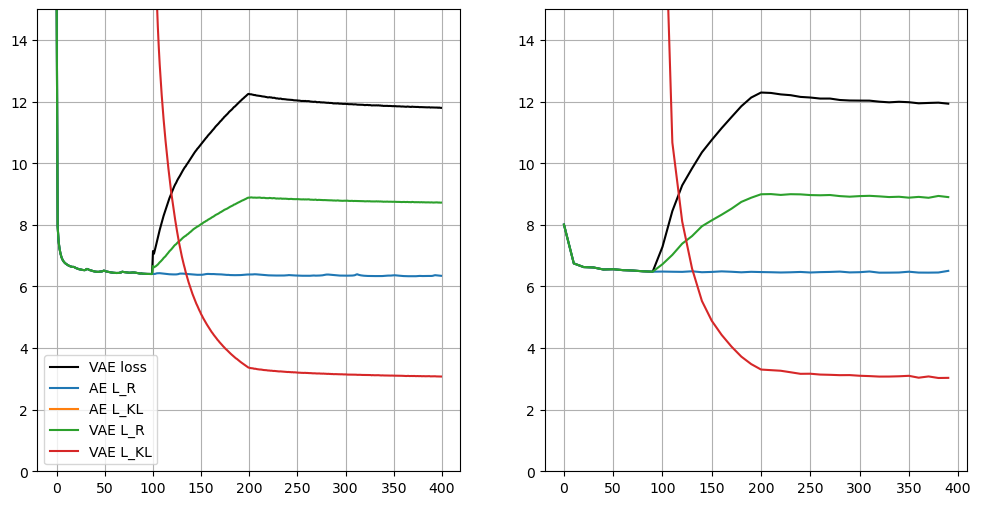

In [80]:
import matplotlib.colors as mcolors

reps = os.listdir(f"results\\VAE")[-2:]
fig = plt.figure(len(reps), figsize = (12, 6))
ef = 60000
ep = 400
D = 50

reps = [f"results\\VAE\\D_{D}-beta_{b}-eff_{ef}-epoch_{ep}" for b in ["0.0", "1.0"]]
AVGS = [pd.read_csv(rep + "\\loss.csv") for rep in reps] 
Vals = [pd.read_csv(rep + "\\validation_loss.csv") for rep in reps] 

AE_losses = np.array(AVGS[0].iloc[:, 1:3]).reshape(400, 300, 2).mean(axis = 1)
VAE_losses = np.array(AVGS[1].iloc[:, 0:3]).reshape(400, 300, 3).mean(axis = 1)

x_val = np.arange(0, 400, 10)
AE_val_losses = np.array(Vals[0].iloc[:, 1:3]).reshape(40, 100, 2).mean(axis = 1)
VAE_val_losses = np.array(Vals[1].iloc[:, 0:3]).reshape(40, 100, 3).mean(axis = 1)

legend = ["VAE loss", "AE L_R", "AE L_KL", "VAE L_R", "VAE L_KL"]
colors = ["k"] + list(mcolors.TABLEAU_COLORS.keys())
plotable = np.array([VAE_losses[:, 0].T] + list(AE_losses.T) + list(VAE_losses[:, 1:].T))
plotable_val = np.array([VAE_val_losses[:, 0].T] + list(AE_val_losses.T) + list(VAE_val_losses[:, 1:].T))


plt.subplot(1, 2, 1)
for v, vals in enumerate(plotable) :
    plt.plot(vals, color = colors[v])
plt.ylim((0, 15))
plt.grid()
plt.legend(legend)
# plt.title("AE losses VS VAE_losses on train dataset")

plt.subplot(1, 2, 2)
for v, vals in enumerate(plotable_val) :
    plt.plot(x_val, vals, color = colors[v])
# plt.title("AE_losses VS VAE_losses on validation dataset")
    
plt.ylim((0, 15))
plt.grid()
plt.savefig(f"results\\IMG\\AE_VAE_loss_comparison.pdf", bbox_inches = "tight")


# 3. Display Latent looks

## 3.1. MNIST

In [23]:
path = r"datas/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = dl.load_datas(path, keys)


X_TRAIN = X_TRAIN.reshape((60000, 1, 28, 28))
X_VAL = X_VAL[:].reshape((10000, 1, 28, 28))


X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

## 3.2. VAE trained Model

In [25]:
D = 50
ef = len(X_TRAIN)
ep = 400
b = 1.0

rep = f"results\\VAE\\D_{D}-beta_{b}-eff_{ef}-epoch_{ep}"
net = torch.load(rep + r"\model.pt", weights_only=False)

In [40]:
%autoreload 2
from libraries.latent import get_MU_LOGVAR, get_Asquare

In [ ]:
batchsize = 10000
MU, LOGVAR = get_MU_LOGVAR(net, X_TRAIN, batchsize)
MU_test, LOGVAR_test = get_MU_LOGVAR(net, X_VAL, batchsize)

In [36]:
MU.shape, LOGVAR.shape, MU_test.shape, LOGVAR_test.shape

((60000, 50), (60000, 50), (10000, 50), (10000, 50))

In [ ]:
Asquare_train = get_Asquare(MU, np.exp(LOGVAR))
Asquare_test = get_Asquare(MU_test, np.exp(LOGVAR_test))

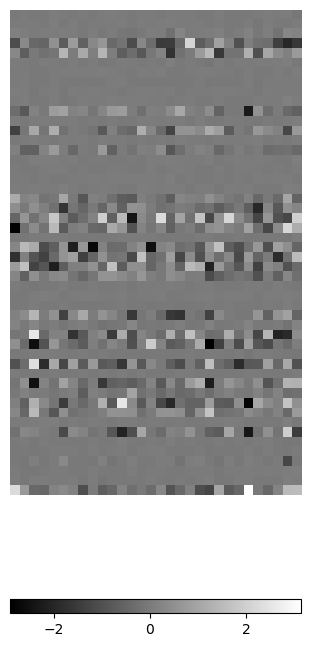

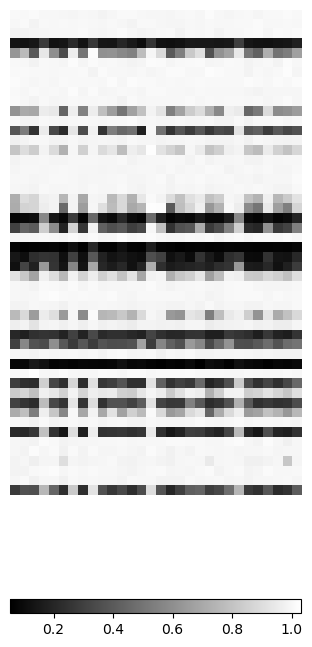

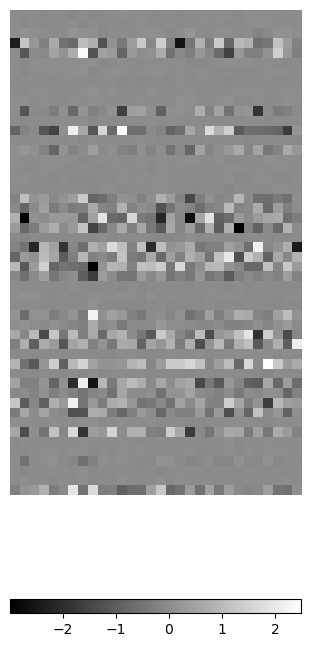

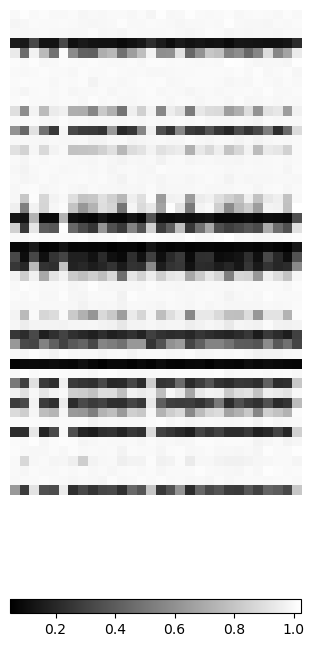

In [67]:
files = ["MU", "SIGMA", "MU_test", "SIGMA_test"]
files_sorted = [file +"_sorted" for file in files]

latents = [MU, np.exp(LOGVAR/2), MU_test, np.exp(LOGVAR_test/2)]

for file, latent in zip(files, latents) :
    plt.figure(figsize = (15, 9))
    plt.imshow(latent[:30].T, cmap = "gray")
    plt.axis("off")
    plt.colorbar(orientation = "horizontal", shrink = 0.25)
    plt.savefig(f"results\\IMG\\{file}.png", bbox_inches = "tight")
    plt.show()

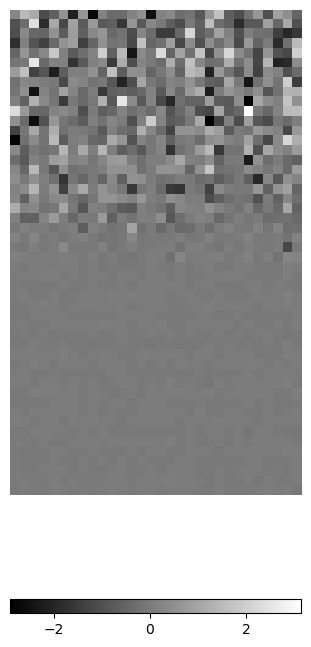

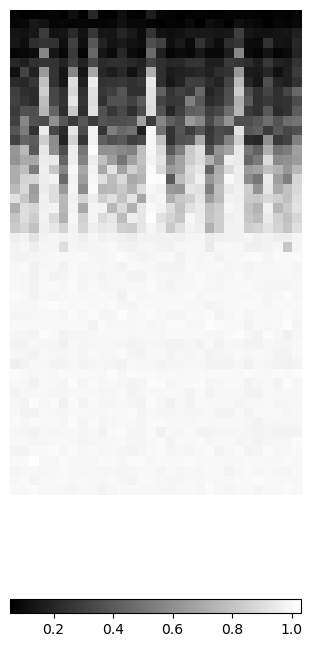

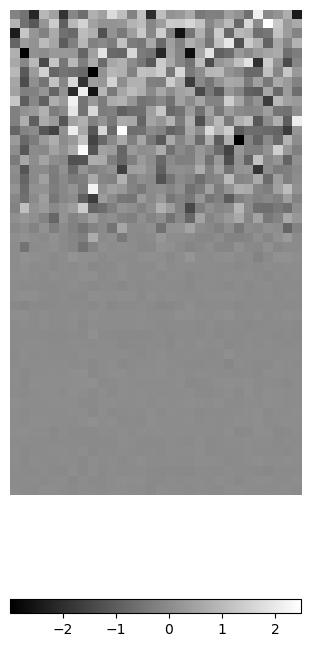

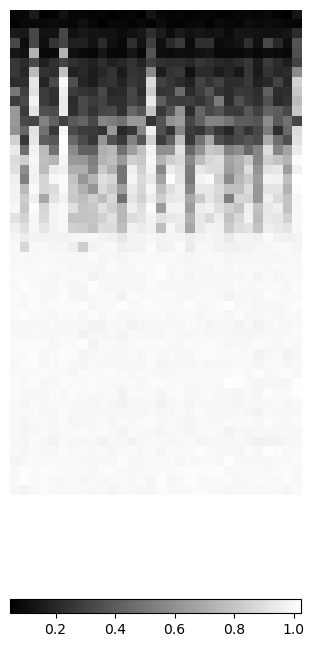

In [68]:
files_sorted = [file +"_sorted" for file in files]
latents_sorted = [MU[:, Asquare_train["index"]], np.exp(LOGVAR/2)[:, Asquare_train["index"]], 
                  MU_test[:, Asquare_test["index"]], np.exp(LOGVAR_test/2)[:, Asquare_test["index"]]]

for file, latent in zip(files_sorted, latents_sorted) :
    plt.figure(figsize = (15, 9))
    plt.imshow(latent[:30].T, cmap = "gray")
    plt.axis("off")
    plt.colorbar(orientation = "horizontal", shrink = 0.25)
    plt.savefig(f"results\\IMG\\{file}.png", bbox_inches = "tight")
    plt.show()

In [91]:
Asquare_train["Tab"] = [f"{val:3.0f}" for val in Asquare_train[0]]
Asquare_test["Tab"] = [f"{val:3.0f}" for val in Asquare_test[0]]

In [92]:
Asquare_train.to_csv(r"results\Asquare\train.csv", index = False)
Asquare_test.to_csv(r"results\Asquare\test.csv", index = False)